# The three-state Kalman observer

This notebook documents the model of Section 5 and Appendix B of the manuscript, checks its equations against the
code (`sdu.model.engine`), and reproduces the model comparison, the predictive checks, the parameters and the sources
of serial dependence (Table 1, Figures 6–7, Appendix B.1–B.4, Table B2).

* **The filter.** The fast-state prediction is $\hat x_i^-=\hat m_{i-1}+F_{1,3}\hat b_{i-1}$ on every trial (first row
  of $\mathbf F$ is $(0,\,1,\,F_{1,3})$): the prior of the current duration is the learned mean.
* **Readout retention $\phi$.** After the update, the observer takes a share $\phi(\mathrm{coh}_i)$ of the previous
  fast deviation into the response. The share depends on the current coherence, which is known by then. Nothing is
  written back into the filter.

Every model has $\phi^L$ and $\phi^H$ free. The space is C1–C15 × S0–S3 × B0–B2, 148 distinct models, labelled
`C-S-B` (e.g. `C9-S0-B2`). All comparisons are within this space.

Part I defines the model and checks the equations against the code. Part II reports the fits.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sdu import paths as SP
from sdu.model import fitting as FF
from sdu.reports import plots as P
from sdu.reports import kalman as R

EXPS = R.EXPS
data = {e: FF.load(e) for e in EXPS}
fits = FF.read_fits()
assert fits.groupby(["exp", "Sub"]).model.nunique().eq(148).all()
FITS = R.Fits(fits, data)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
P.use_style()

# Part I. Model definition

## Complete model equations

Symbols as in Appendix B.1.

**States.** $\mathbf s_i=[\hat x_i,\,\hat m_i,\,\hat b_i]^\top$:
* $\hat x$ is the fast state, the current duration estimate;
* $\hat m$ is the slow state, the learned mean;
* $\hat b$ is the bias state.

$\mathbf s_i^-$ is the prediction and $\mathbf s_i$ the posterior. $s_i$ is the presented duration on trial $i$.
The fast deviation is $\hat f_i=\hat x_i-\hat m_i$.

**State evolution.**

$$
\mathbf s_i^-=\mathbf F\,\mathbf s_{i-1},\qquad
\mathbf F=\begin{bmatrix}0&1&F_{1,3}\\0&1&0\\0&0&\lambda\end{bmatrix},\qquad
\mathbf P_i^-=\mathbf F\,\mathbf P_{i-1}\mathbf F^\top+\mathbf Q_i,
$$

$$
\mathbf Q_i=\operatorname{diag}\big(q_1^{\text{eff}},q_2^{\text{eff}},q_3^{\text{eff}}\big),\qquad
q_j^{\text{eff}}=q_j\cdot\exp\big(\alpha_{q_j}(1-\mathrm{coh}_i)\big)
\ \text{(for the noises freed by the C level; otherwise } q_j^{\text{eff}}=q_j).
$$

So $\hat x_i^-=\hat m_{i-1}+F_{1,3}\,\hat b_{i-1}$, $\hat m_i^-=\hat m_{i-1}$ and $\hat b_i^-=\lambda\hat b_{i-1}$.

**Observation and update.** $\mathbf H=[1,0,0]$. The measurement is the presented duration, $z_i=s_i$; $R_i$ sets the
gain and adds no noise to $z_i$.

$$
R_i=\begin{cases}1 & \mathrm{coh}_i\ge 0.5\\ r_{\text{low}} & \mathrm{coh}_i<0.5\end{cases}\quad\text{(if the C level frees }R\text{; otherwise }R_i=1),
$$

$$
\mathbf K_i=\mathbf P_i^-\mathbf H^\top\big(\mathbf H\mathbf P_i^-\mathbf H^\top+R_i\big)^{-1},\qquad
\mathbf s_i=\mathbf s_i^-+\mathbf K_i\big(z_i-\mathbf H\,\mathbf s_i^-\big),\qquad
\mathbf P_i=(\mathbf I-\mathbf K_i\mathbf H)\,\mathbf P_i^- .
$$

$K_i^{(x)}$ and $K_i^{(m)}$ are the components of $\mathbf K_i$ for $\hat x$ and $\hat m$. Only $(\mathbf s_i,\mathbf P_i)$
is carried to trial $i+1$.

**Readout.** This is the only place of $\phi$:

$$
\hat u_i=\hat x_i+\big(1-K_i^{(x)}\big)\,\phi_i\,\hat f_{i-1},\qquad \hat f_{i-1}=\hat x_{i-1}-\hat m_{i-1},\qquad
\phi_i=\begin{cases}\phi^L & \mathrm{coh}_i<0.5\\ \phi^H & \mathrm{coh}_i\ge 0.5\\ 0 & \text{S3 and }\mathrm{coh}_i\neq\mathrm{coh}_{i-1}\end{cases}
$$

It is the posterior mean under the readout prior $\tilde x_i^-=\hat x_i^-+\phi_i\hat f_{i-1}$ with the filter's gain:
$\tilde x_i^-+K_i^{(x)}(z_i-\tilde x_i^-)=\hat x_i+(1-K_i^{(x)})\,\phi_i\hat f_{i-1}$. The readout is therefore still
precision weighted. It happens after the stimulus, when $\mathrm{coh}_i$ is known. With $\phi=0$ it is
the filter's estimate, $\hat u_i=\hat x_i$.

**Response.** With $d_0^{\text{eff}}=d_0+\alpha_{d_0}(1-\mathrm{coh}_i)$:

$$
y_i=\hat u_i+d_0^{\text{eff}}+\varepsilon_i\quad\text{(B0, B1)},\qquad
y_i=\hat u_i+b_i+d_0^{\text{eff}}+\varepsilon_i\quad\text{(B2)},\qquad \varepsilon_i\sim\mathcal N(0,\sigma_e^2).
$$

Under B2, $b_i=\lambda b_{i-1}+\eta_i$ with $\eta_i\sim\mathcal N(0,q_3^{\text{eff}})$ is a slowly drifting bias added to
the response. The observer never sees $b_i$, so it is written without a hat; the
likelihood integrates it out.

**What it predicts.** Central tendency, the slope on the current duration, is $\partial\hat u_i/\partial s_i=K_i^{(x)}$
in every model and does not depend on $\phi$. Serial dependence is the slope on the previous duration, with the earlier
durations held fixed. Without a bias in the prediction (B0, B2) and without the state reset (S0, S2, S3) it has two
paths:

$$
\frac{\partial\hat u_i}{\partial s_{i-1}}=\big(1-K_i^{(x)}\big)\Big[\underbrace{K_{i-1}^{(m)}}_{\text{memory}}
+\underbrace{\phi_i\,\big(K_{i-1}^{(x)}-K_{i-1}^{(m)}\big)}_{\text{readout}}\Big].
$$

The current coherence can change serial dependence in two ways:
* through the factor $(1-K_i^{(x)})$, if the C level makes the gain depend on coherence ($q_1$ or $R$);
* through $\phi^L\neq\phi^H$.

Under B2 the bias state is not part of the observer's filter ($F_{1,3}=0$), so $q_3$ does not change any gain. Because
$\phi$ multiplies once, earlier trials are not passed on through products of $\phi$.

S1 and B1 each change the bracket. For all levels,

$$
\frac{\partial\hat u_i}{\partial s_{i-1}}=\big(1-K_i^{(x)}\big)\Big[\big(1-\gamma\,\mathrm{sw}_i\big)\,K_{i-1}^{(m)}
+\phi_i\,\big(K_{i-1}^{(x)}-K_{i-1}^{(m)}\big)+F_{1,3}\,K_{i-1}^{(b)}\Big].
$$

* $\mathrm{sw}_i=1$ on a switch trial under S1 and 0 otherwise: the reset removes the share $\gamma$ of the learned mean,
  and with it of the previous duration.
* $K^{(b)}$ is the gain of the bias state (B1, $F_{1,3}=1$).
* Under S2, $K_i$ on a switch trial is the reduced gain.

## Dimensions

Every model is one level of each of three dimensions. Each coherence modulation is fitted as a Low/High ratio in
$[0.1,10]$: $q_j^{\text{eff}}(\text{Low})/q_j^{\text{eff}}(\text{High})=\exp(0.4\,\alpha_{q_j})$ and $r_{\text{low}}/1$.

### C: which noise depends on coherence (15 levels)

| C | $q_1$ fast state ($\alpha_{q_1}$) | $q_2$ slow state ($\alpha_{q_2}$) | $q_3$ bias state ($\alpha_{q_3}$) | $R$ measurement ($r_{\text{low}}$) | extra parameters | contains | with B0 |
|---|:-:|:-:|:-:|:-:|:-:|---|:-:|
| C1 | ✓ | | | | 1 | — | yes |
| C2 | | ✓ | | | 1 | — | yes |
| C3 | | | ✓ | | 1 | — | no |
| C4 | | | | ✓ | 1 | — | yes |
| C5 | ✓ | | | ✓ | 2 | C1, C4 | yes |
| C6 | | ✓ | | ✓ | 2 | C2, C4 | yes |
| C7 | | | ✓ | ✓ | 2 | C3, C4 | no |
| C8 | ✓ | ✓ | | | 2 | C1, C2 | yes |
| C9 | ✓ | | ✓ | | 2 | C1, C3 | no |
| C10 | | ✓ | ✓ | | 2 | C2, C3 | no |
| C11 | ✓ | ✓ | | ✓ | 3 | C1, C2, C4, C5, C6, C8 | yes |
| C12 | ✓ | | ✓ | ✓ | 3 | C1, C3, C4, C5, C7, C9 | no |
| C13 | | ✓ | ✓ | ✓ | 3 | C2, C3, C4, C6, C7, C10 | no |
| C14 | ✓ | ✓ | ✓ | | 3 | C1, C2, C3, C8, C9, C10 | no |
| C15 | ✓ | ✓ | ✓ | ✓ | 4 | all | no |

"Contains" means the level reduces to the smaller one when the extra modulations are 0 ($r_{\text{low}}=1$). A C level
with $q_3$ is not combined with B0, because without a bias state $q_3$ does nothing.

### S: what happens on a coherence switch, $\mathrm{coh}_i\neq\mathrm{coh}_{i-1}$ (4 levels)

On repeat trials every S level equals S0.

| S | name | on a switch trial | extra parameters |
|---|---|---|:-:|
| S0 | no switch effect | nothing | 0 |
| S1 | state reset | before the prediction, $\hat m\leftarrow(1-\gamma)\,\hat m+\gamma\,\mu_0$ and $\mathbf P\leftarrow\mathbf A\mathbf P\mathbf A^\top$ with $\mathbf A=\operatorname{diag}(1,\,1-\gamma,\,1)$, so the variance of the mean becomes $(1-\gamma)^2P^{(m)}$; $\hat x$ is unchanged at that moment, and the readout uses $\hat f_{i-1}$ from before the reset | $\gamma$ |
| S2 | gain reduction | $\mathbf K\leftarrow(1-\kappa)\,\mathbf K$, and $\mathbf P$ is updated with the reduced gain | $\kappa$ |
| S3 | readout reset | $\phi_i=0$: the previous fast deviation is not borrowed | 0 |

### B: the bias state (3 levels)

| B | where the bias acts | equations | extra parameters |
|---|---|---|:-:|
| B0 | none | response $\hat u_i+d_0^{\text{eff}}$ | 0 |
| B1 | in the observer's prediction | $F_{1,3}=1$: $\hat x_i^-=\hat m_{i-1}+\hat b_{i-1}$; the observer updates $\hat b$ from the measurement | $\lambda,\ q_3$ |
| B2 | in the response, latent | $F_{1,3}=0$; response $\hat u_i+b_i+d_0^{\text{eff}}$ with $b_i=\lambda b_{i-1}+\eta_i$, $\eta_i\sim\mathcal N(0,q_3^{\text{eff}})$; the observer never sees $b_i$ | $\lambda,\ q_3$ |

### Parameters shared by every model

| parameter | meaning |
|---|---|
| $q_1,\ q_2$ | process noise of the fast and slow states |
| $\phi^L,\ \phi^H$ | share of the previous fast deviation borrowed at the readout, current Low / High, in $[0,1]$ |
| $d_0,\ \alpha_{d_0}$ | response offset and its coherence modulation, $d_0^{\text{eff}}=d_0+\alpha_{d_0}(1-\mathrm{coh})$ |
| $\sigma_e$ | response noise |

The number of parameters $k$ is 7 shared, plus 1–4 (C), plus 1 (S1, S2), plus 2 (B1, B2). It runs from 8 (e.g.
C1-S0-B0) to 14 (C15-S1-B2). Model count: 15 C × 4 S × 3 B = 180, minus the 8 C levels with $q_3$ × 4 S under B0, gives
148.

## Derivation in four steps

This is the simplest case: no bias in the prediction (B0 or B2, so $F_{1,3}=0$) and no switch rule (S0). Each step is
one line.

**Step 1 — Prediction.** The fast state starts from the learned mean:

$$\hat x_i^-=\hat m_{i-1}.$$

**Step 2 — Update.** The new estimate is a weighted average of the learned mean and the current duration, and the
mean moves a little toward the current duration:

$$
\hat x_i=\big(1-K_i^{(x)}\big)\,\hat m_{i-1}+K_i^{(x)}\,s_i,\qquad
\hat m_i=\hat m_{i-1}+K_i^{(m)}\,\big(s_i-\hat m_{i-1}\big).
$$

$K^{(x)}$ is large (about .5–.6) and $K^{(m)}$ small (about .05–.2): the estimate follows the current duration, the
mean changes slowly.

**Step 3 — Fast deviation.** How far the estimate was pulled beyond the mean by this duration:

$$\hat f_i=\hat x_i-\hat m_i=\big(K_i^{(x)}-K_i^{(m)}\big)\,\big(s_i-\hat m_{i-1}\big).$$

**Step 4 — Readout.** The response borrows a share $\phi_i$ of the previous trial's fast deviation:

$$\hat u_i=\hat x_i+\big(1-K_i^{(x)}\big)\,\phi_i\,\hat f_{i-1}.$$

**Result: the two slopes.** Inserting steps 2 and 3 into step 4 gives two slopes.

*Central tendency*, the slope on the current duration $s_i$, is how much the current duration counts. $\phi$ plays no
role:

$$\frac{\partial\hat u_i}{\partial s_i}=K_i^{(x)}.$$

*Serial dependence*, the slope on the previous duration $s_{i-1}$, is the weight left for the past times what the past
left behind:

$$
\frac{\partial\hat u_i}{\partial s_{i-1}}
=\underbrace{\big(1-K_i^{(x)}\big)}_{\text{weight left for the past}}
\Big[\underbrace{K_{i-1}^{(m)}}_{\text{memory path}}
+\underbrace{\phi_i\big(K_{i-1}^{(x)}-K_{i-1}^{(m)}\big)}_{\text{readout path}}\Big].
$$

The bracket has two parts:

* **memory path** $K_{i-1}^{(m)}$: the previous duration moved the learned mean, and the mean enters every estimate;
* **readout path** $\phi_i\,(K_{i-1}^{(x)}-K_{i-1}^{(m)})$: the previous fast deviation, borrowed in the proportion
  $\phi_i$ chosen by the **current** coherence.

The current coherence can therefore change serial dependence in two ways: through $1-K_i^{(x)}$, if coherence changes
the gain, or through $\phi^L\neq\phi^H$.

The readout path borrows from the previous trial only; there is no chain of $\phi$. Earlier durations still enter it
through the mean, because $\hat f_{i-1}$ is measured from $\hat m_{i-2}$ (step 3). Their weight in the readout path is
small and negative; at lag 2 it is $-(1-K_i^{(x)})\,\phi_i\,(K_{i-1}^{(x)}-K_{i-1}^{(m)})\,K_{i-2}^{(m)}$.

<details>
<summary>The gains in closed form</summary>

With $P^{(m)}_{i-1}$ the uncertainty of the learned mean and $S_i=P^{(m)}_{i-1}+q^{\text{eff}}_{1,i}+R_i$:

$$
K_i^{(x)}=\frac{P^{(m)}_{i-1}+q^{\text{eff}}_{1,i}}{S_i},\qquad
K_i^{(m)}=\frac{P^{(m)}_{i-1}}{S_i},\qquad
P^{(m)}_i=P^{(m)}_{i-1}+q^{\text{eff}}_{2,i}-\frac{\big(P^{(m)}_{i-1}\big)^2}{S_i}.
$$

So $K_i^{(x)}-K_i^{(m)}=q^{\text{eff}}_{1,i}/S_i$: the fast deviation, and with it the readout path, exists only because
$q_1>0$.

</details>

**Other levels.** The slope formulas above hold for B0 and B2 with S0, S2 and S3. The general serial-dependence slope
is in the model equations.
* **S1:** on a switch, $\hat m$ is first moved toward $\mu_0$ and its variance is scaled by $(1-\gamma)^2$. The memory
  path becomes $(1-\gamma)K_{i-1}^{(m)}$. $\hat f_{i-1}$ is taken before the reset, so the readout path keeps its form.
* **S2:** on a switch, both gains are multiplied by $1-\kappa$. Both slopes keep their form, with the reduced gains.
* **S3:** on a switch, $\phi_i=0$, so the readout path is 0.
* **B1:** $\hat b$ is added to the prediction ($F_{1,3}=1$). The bracket gains the term $K_{i-1}^{(b)}$, and the gains
  no longer have the scalar closed form.
* **B2:** $b_i$ is added to the response. It changes neither slope.

The first cell below checks the four steps against the engine: it recomputes every response from the four lines and
compares them with the engine's output. The second cell checks the two slopes for one model of every S and B level.
It moves one duration by 0.1 s and compares the change of the engine's readout with $K_i^{(x)}$ (`central_tendency`)
and with the general serial-dependence slope (`serial_dependence`); `linear_maps` compares that slope with the
engine's $\mathbf c_i\,\mathbf K_{i-1}$. All entries are maximum absolute differences.

In [2]:
display(R.check_closed_form(FITS, [(1, "C9-S0-B2"), (2, "C4-S3-B2"), (2, "C3-S3-B2")]))

,experiment,Sub,model,max_abs_diff
0,Exp 1,26578,C9-S0-B2,2.220e-16
1,Exp 1,109550,C9-S0-B2,2.220e-16
2,Exp 2,2046,C4-S3-B2,4.441e-16
3,Exp 2,62573,C4-S3-B2,4.441e-16
4,Exp 2,2046,C3-S3-B2,2.188e-12
5,Exp 2,62573,C3-S3-B2,2.220e-16


In [3]:
display(R.check_slopes(FITS, [(1, "C9-S0-B2"), (2, "C3-S3-B2"), (1, "C15-S1-B2"), (2, "C15-S2-B2"),
                              (1, "C11-S1-B0"), (2, "C15-S0-B1"), (2, "C15-S1-B1")]))

,experiment,Sub,model,central_tendency,serial_dependence,linear_maps
0,Exp 1,26578,C9-S0-B2,2.998e-15,3.006e-15,2.776e-17
1,Exp 1,109550,C9-S0-B2,3.053e-15,2.831e-15,5.551e-17
2,Exp 2,2046,C3-S3-B2,2.998e-15,2.897e-15,2.776e-17
3,Exp 2,62573,C3-S3-B2,2.831e-15,3.665e-15,5.551e-17
4,Exp 1,26578,C15-S1-B2,2.887e-15,3.969e-15,2.776e-17
5,Exp 1,109550,C15-S1-B2,2.415e-15,4.299e-15,5.551e-17
6,Exp 2,2046,C15-S2-B2,2.276e-15,2.743e-15,2.776e-17
7,Exp 2,62573,C15-S2-B2,4.052e-15,2.671e-15,5.551e-17
8,Exp 1,26578,C11-S1-B0,2.665e-15,4.278e-15,6.939e-18
9,Exp 1,109550,C11-S1-B0,2.665e-15,4.198e-15,2.776e-17


## Factor levels: hypotheses and assumptions

Each dimension asks one question, and each level is one answer to it. The statements about gains use the closed form
of the derivation (B0 or B2): $K_i^{(x)}=(P^{(m)}_{i-1}+q^{\text{eff}}_{1,i})/S_i$ and $K_i^{(m)}=P^{(m)}_{i-1}/S_i$, with
$S_i=P^{(m)}_{i-1}+q^{\text{eff}}_{1,i}+R_i$.

### Assumptions shared by all 148 models

* **Standard Kalman observer on the linear scale.** One prediction and one update per trial, on durations in seconds.
* **Noise-free measurement.** $z_i=s_i$. $R_i$ is the reliability the observer assigns to the measurement: it sets the
  gain and adds no noise.
* **Independent process noises.** $\mathbf Q$ is diagonal.
* **Coherence is known.** The observer knows the coherence of the current trial (Low .3, High .7) when it updates and
  when it reads out.
* **Readout persistence in every model.** $\phi^L$ and $\phi^H$ are always free, so every C, S and B level is tested
  on top of the readout mechanism.
* **Response.** An offset with a coherence difference ($d_0$, $\alpha_{d_0}$) and constant response noise $\sigma_e$.
* **No fixed direction.** Each coherence modulation is a Low/High ratio in $[0.1,10]$. The fit decides whether Low is
  larger or smaller.

### C: where does coherence change the observer's noise?

A C level names the noise terms that may differ between Low and High trials. There are four places, and C1–C4 are the
four single-place hypotheses. The effects below are for a Low/High ratio above 1; they reverse for a ratio below 1.

| C | noise | hypothesis | what it changes |
|---|---|---|---|
| C1 | $q_1$, fast state | Under Low coherence the observer expects the current duration to lie further from the learned mean. | On a Low trial $K^{(x)}$ is higher and $K^{(m)}$ lower: weaker central tendency, less weight left for the past ($1-K^{(x)}$), and a larger fast deviation. |
| C2 | $q_2$, slow state | Under Low coherence the observer expects the mean itself to drift more. | $q_2$ is added to $P^{(m)}$ after the update, so both gains are higher on the trial *after* a Low trial. This is an effect of the previous coherence, not of the current one. |
| C3 | $q_3$, bias state | The bias changes more from trial to trial under Low coherence. What this means depends on B (below). | B2: only the drift of the response bias, so response variability differs by coherence; no gain and neither slope changes. B1: the observer's gains change, from the next trial on. B0: nothing, so these models are not in the space. |
| C4 | $R$, measurement | Under Low coherence the observer treats the duration measurement as less reliable. This is reliability weighting, the standard Bayesian account. | On a Low trial both gains are lower: stronger central tendency and, through $1-K^{(x)}$, stronger serial dependence. A Low trial also leaves a smaller trace in the next one. |

C5–C15 combine these places. A combined level is not a new hypothesis; it tests whether more than one place is needed.

**What C3 means in the selected models.** C3-S0-B2 and C3-S3-B2 say that coherence does not enter the observer's
filter at all, so the gains are the same for Low and High. Coherence acts in three places outside the filter: the
readout persistence ($\phi^L$, $\phi^H$), the response offset ($\alpha_{d_0}$) and the drift of the response bias
($q_3$).

### S: does a change of coherence have an effect of its own?

| S | hypothesis | assumptions | what it changes on a switch trial |
|---|---|---|---|
| S0, no switch effect | No. Coherence acts only through its level on the current trial. | none | Nothing: serial dependence depends on the current coherence, not on the transition. |
| S1, state reset | After a switch the observer partly gives up the learned mean and falls back on the long-run mean. | The fallback is the design mean $\mu_0=1.2$ s, by a fixed share $\gamma$. The variance of the mean shrinks with it, so the reverted mean counts as more certain. | The memory path loses the share $\gamma$. Both current gains are lower, so the pull toward the reverted mean is stronger. The readout path keeps its form. |
| S2, gain reduction | After a switch the new measurement counts less. | Both gains are multiplied by $1-\kappa$. The reduced gain is not the optimal one, and $\mathbf P$ is updated with it. | Stronger central tendency and more weight left for the past, so serial dependence is *stronger*. The switch trial also leaves a smaller trace in the next one. |
| S3, readout reset | The fast deviation is carried over only within the same coherence context. | $\phi_i=0$. The filter is untouched, and there is no parameter. | The readout path is 0, so serial dependence falls to the memory path. Repeat trials keep both paths. |

### B: is there a slow bias, and where does it act?

| B | hypothesis | assumptions | what it changes |
|---|---|---|---|
| B0, none | There is no slow bias. | Response noise is independent across trials. | All history effects come from the mean and the fast deviation. |
| B1, prediction | The observer itself assumes a slowly changing bias in its predictions and estimates it from the prediction errors. | $\hat b$ is an AR(1) state ($\lambda$, $q_3$) inside the filter, $F_{1,3}=1$. | A third history path, $K_{i-1}^{(b)}$ in the serial-dependence slope. The gains depend on $\lambda$ and $q_3$. |
| B2, response | The bias arises after the estimate, at the response. The observer does not perceive or correct it. | $b_i$ is a latent AR(1) process ($\lambda$, $q_3$) added to the response, independent of the durations. | No gain and neither slope. The responses drift slowly, so the response residuals are correlated across trials. The likelihood integrates over $b_i$. |

**Reading a label.** C3-S3-B2 is:
* C3: coherence changes only the drift of the response bias;
* S3: after a coherence switch the previous fast deviation is not borrowed;
* B2: the slow bias is in the response.

# Part II. Fits of the 148 models

Each model was fitted by maximum likelihood to every participant (13 starts: the default point, 11 random points and
$\phi^L=\phi^H=0$) and simulated 20 times on the participant's own sequence (`scripts/model/fit_models.py`;
stored in `results/model/fits/all.csv`). AIC is the mean per
participant; $\Delta$AIC is relative to the best of the 148 models. $z$ = (model mean − data mean) / SEM of the data.
`focal` is the prespecified contrast (Exp 1: Low − High serial dependence; Exp 2: L→L − the other three transitions),
`all three` adds the central-tendency and response-variability checks; $|z|<1.5$ throughout.

In [4]:
T, STATS = R.load_screening(SP.MODEL_COMPARISON)
print(T.groupby("exp").size().to_dict(), "models per experiment;", {EXPS[e]: len(STATS[e]) for e in EXPS}, "statistics")

{1: 148, 2: 148} models per experiment; {'Exp 1': 14, 'Exp 2': 13} statistics


## 1. AIC

The ten best models of each experiment, then every level of each dimension: the best $\Delta$AIC among its models, and
how many of its models pass the focal contrast and all three checks.

In [5]:
for e in EXPS:
    print(EXPS[e])
    display(R.top_models(T, e))
for dim in ("C", "S", "B"):
    display(R.by_dimension(T, dim))

Exp 1


,label,k,dAIC,passes_focal_contrasts,passes_all_three,n_within,sum_z2
rank,,,,,,,
1,C9-S0-B2,11,0.000,True,False,11.0,21.301
2,C1-S0-B2,10,0.052,True,False,7.0,30.633
3,C3-S0-B2,10,0.120,True,False,10.0,22.551
4,C4-S0-B2,10,0.144,True,False,11.0,19.515
5,C7-S0-B2,11,0.166,True,False,9.0,24.195
6,C9-S3-B2,11,0.575,False,False,7.0,54.821
7,C3-S3-B2,10,0.646,False,False,8.0,52.378
8,C7-S3-B2,11,0.735,False,False,7.0,44.518
9,C4-S3-B2,10,0.779,False,False,7.0,41.643


Exp 2


,label,k,dAIC,passes_focal_contrasts,passes_all_three,n_within,sum_z2
rank,,,,,,,
1,C3-S0-B2,10,0.000,False,False,10.0,15.710
2,C4-S0-B2,10,0.226,False,False,9.0,19.809
3,C7-S0-B2,11,0.445,False,False,9.0,22.524
4,C3-S3-B2,10,0.556,True,False,11.0,7.471
5,C4-S3-B2,10,0.623,True,True,13.0,5.341
6,C7-S3-B2,11,0.951,True,False,12.0,7.327
7,C9-S0-B2,11,0.954,False,False,10.0,14.747
8,C5-S0-B2,11,1.102,False,False,10.0,17.014
9,C9-S3-B2,11,1.133,True,True,13.0,4.697


,Exp 1 models,Exp 2 models,Exp 1 best_dAIC,Exp 2 best_dAIC,Exp 1 focal,Exp 2 focal,Exp 1 all_three,Exp 2 all_three
C,,,,,,,,
C1,12,12,0.052,1.224,7,3,0,1
C2,12,12,1.971,1.607,2,3,0,1
C3,8,8,0.120,0.000,3,2,0,0
C4,12,12,0.144,0.226,8,3,3,1
C5,12,12,0.909,1.102,8,4,1,1
C6,12,12,1.846,1.930,3,3,0,1
C7,8,8,0.166,0.445,6,2,0,0
C8,12,12,1.651,1.858,3,3,0,0
C9,8,8,0.000,0.954,4,2,0,1


,Exp 1 models,Exp 2 models,Exp 1 best_dAIC,Exp 2 best_dAIC,Exp 1 focal,Exp 2 focal,Exp 1 all_three,Exp 2 all_three
S,,,,,,,,
S0,37,37,0.000,0.000,21,0,1,0
S1,37,37,1.375,1.254,23,2,1,0
S2,37,37,1.751,1.522,20,0,2,0
S3,37,37,0.575,0.556,0,37,0,12


,Exp 1 models,Exp 2 models,Exp 1 best_dAIC,Exp 2 best_dAIC,Exp 1 focal,Exp 2 focal,Exp 1 all_three,Exp 2 all_three
B,,,,,,,,
B0,28,28,21.008,15.071,12,7,4,2
B1,60,60,23.599,16.386,19,17,0,1
B2,60,60,0.000,0.000,33,15,0,9


**Reading.**
* **B.** B2 is clearly preferred: B0 and B1 are at least 15 AIC units worse.
* **S.** Experiment 1 prefers S0. In Experiment 2, only the S3 models match the focal contrast.
* **C.** The C level is not identified: the best models of several C levels lie within a fraction of an AIC unit.

## 2. Selected models: C3-S0-B2 (Experiment 1) and C3-S3-B2 (Experiment 2)

S and B follow from §1. For C, the table shows all 15 C levels, each with the selected S and B. The gain columns are the mean current gain under Low and High at the fitted parameters, and the ratio
$(1-K^{(x)}_L)/(1-K^{(x)}_H)$ is the factor by which a coherence-dependent gain would scale serial dependence.

In [6]:
SEL = {1: "C3-S0-B2", 2: "C3-S3-B2"}
display(R.c_level_comparison(FITS, T, SEL, c_levels=[f"C{i}" for i in range(1, 16)]))
a = fits[(fits.exp == 2) & (fits.model == "C9-S3-B2")].ratio_q1
print(f"Exp 2 C9-S3-B2: q1 Low/High ratio median {a.median():.2f}, above 1 for {(a > 1).sum()}/{len(a)} participants")

,experiment,model,rank,k,dAIC,z_focal,z_HH,response_variability,all_three,Kx_Low,Kx_High,gain_factor
0,Exp 1,C1-S0-B2,2,10,0.052,-1.386,1.841,False,False,0.610,0.617,1.017
1,Exp 1,C2-S0-B2,29,10,1.971,-1.483,1.670,True,False,0.613,0.614,1.001
2,Exp 1,C3-S0-B2,3,10,0.120,-0.828,1.552,True,False,0.613,0.614,1.002
3,Exp 1,C4-S0-B2,4,10,0.144,-1.138,1.332,False,False,0.610,0.615,1.013
4,Exp 1,C5-S0-B2,10,11,0.909,-1.146,1.818,False,False,0.608,0.617,1.026
5,Exp 1,C6-S0-B2,25,11,1.846,-1.851,1.975,False,False,0.611,0.615,1.012
6,Exp 1,C7-S0-B2,5,11,0.166,-0.971,1.709,True,False,0.611,0.617,1.016
7,Exp 1,C8-S0-B2,20,11,1.651,-1.233,1.489,False,False,0.612,0.617,1.013
8,Exp 1,C9-S0-B2,1,11,0.000,-0.880,1.197,True,False,0.610,0.618,1.020
9,Exp 1,C10-S0-B2,28,11,1.954,-2.070,1.964,True,False,0.614,0.614,1.001


Exp 2 C9-S3-B2: q1 Low/High ratio median 0.97, above 1 for 11/22 participants


**Why C3.**
* **No C level produces the current-coherence effect.** At the fitted parameters the gain hardly depends on coherence:
  $(1-K^{(x)}_L)/(1-K^{(x)}_H)$ stays near 1. The effect comes from the readout ($\phi$, and in Experiment 2 the S3 reset).
* **AIC and parameters.** C3 is within a fraction of an AIC unit of the best C level and is tied for the smallest
  parameter count (with C1, C2 and C4).
* **Response variability.** In Experiment 1 the C levels without $q_3$ (C1, C4) fail the response-variability check,
  because they underestimate the Low residual SD. A Low/High ratio on $q_3$ makes the report's bias noise larger under
  Low.
* **Experiment 2.** C9-S3-B2 passes all three checks where C3-S3-B2 narrowly does not: H→H $z$ is on either side of
  1.5. Its extra ratio $q_1^L/q_1^H$ has median 0.97, so it reduces to C3.

## 3. Behavioural checks: data and the C3 models

The selected models of §2. The predictive check uses the fitted
parameters. 100 cohorts are simulated. In each cohort, every participant is simulated once with their
fitted parameters, on their own trial sequence and validity mask (`scripts/model/predictive_checks.py`). The line is
the mean over cohorts, and the band is the central 95% range across cohorts. Data are the participant mean ± SEM.

### 3.1 Summary by current coherence

* **Central tendency:** the negative slope on the current duration ($-$`b1`), so a taller bar means stronger central
  tendency.
* **Serial dependence:** the slope on the previous duration, `b2` (main-text Eq. 2).
* **Response variability:** the residual SD, `rsd`.

Filled bars show the data mean ± SEM. Hatched bars show the model mean over cohorts with its 95% cohort range.

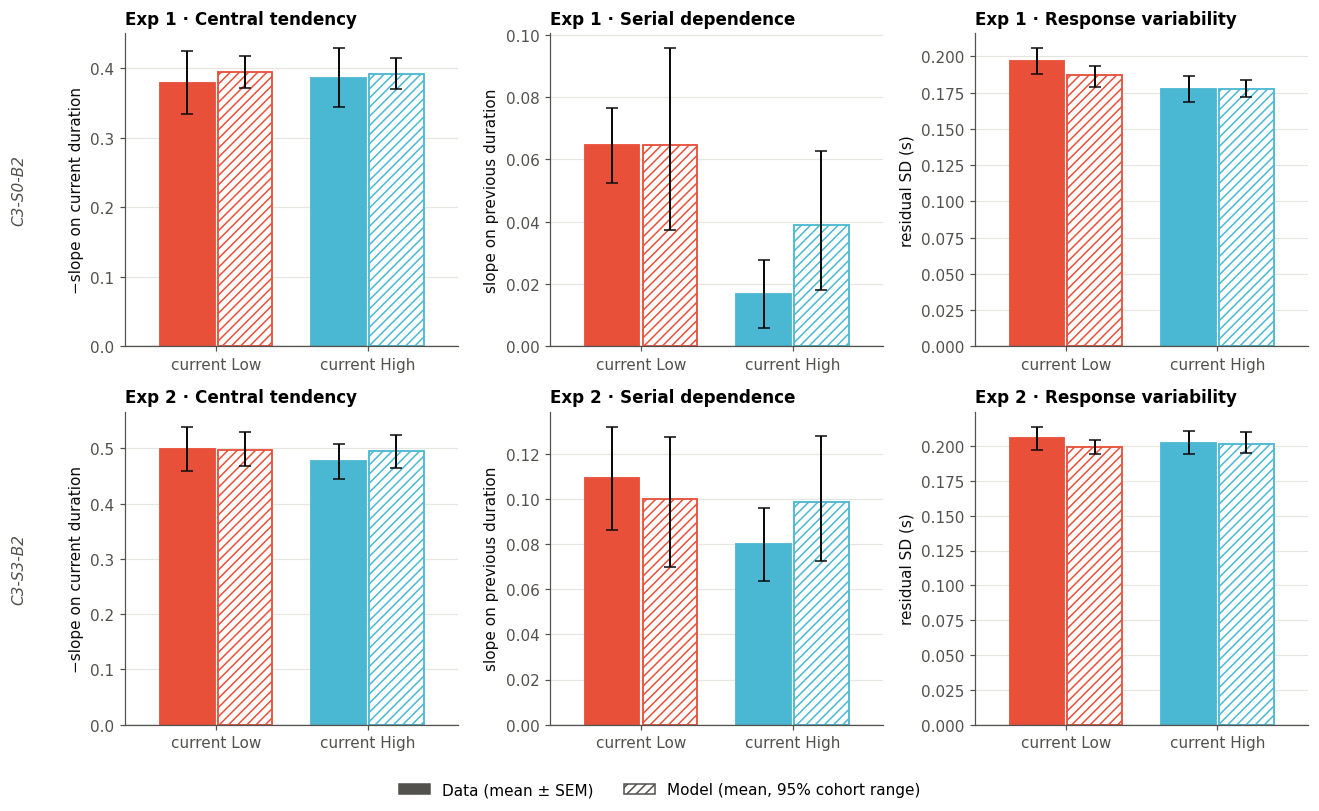

observed  observed_sem  simulated     lo     hi
experiment model    statistic                                                 
Exp 1      C3-S0-B2 b1_Low       -0.379         0.045     -0.394 -0.418 -0.372
                    b1_High      -0.387         0.042     -0.391 -0.415 -0.370
                    b2_Low        0.065         0.012      0.065  0.037  0.096
                    b2_High       0.017         0.011      0.039  0.018  0.063
                    rsd_Low       0.197         0.009      0.187  0.179  0.194
                    rsd_High      0.177         0.009      0.178  0.172  0.184
Exp 2      C3-S3-B2 b1_Low       -0.499         0.040     -0.498 -0.530 -0.468
                    b1_High      -0.477         0.031     -0.496 -0.525 -0.465
                    b2_Low        0.109         0.023      0.100  0.070  0.127
                    b2_High       0.080         0.016      0.099  0.073  0.128
                    rsd_Low       0.205         0.009      0.199  0.194  0.205
                    rsd_High      0.203         0.008      0.202  0.195  0.210

In [7]:
PPC = SP.PREDICTIVE_CHECKS
ppc_s = pd.read_csv(PPC / "summary.csv")
ppc_c = pd.read_csv(PPC / "duration_curves.csv")
ppc_h = pd.read_csv(PPC / "history_curves.csv")
assert ppc_s.n_cohorts.eq(100).all() and ppc_c.n_cohorts.eq(100).all() and ppc_h.n_cohorts.eq(100).all()
PPC_MODEL = SEL
R.plot_summary_bars(ppc_s, PPC_MODEL)
plt.show()
display(ppc_s.drop(columns=["exp", "n_cohorts"]).set_index(["experiment", "model", "statistic"]))

### 3.2 Duration-resolved curves (Appendix B.4, Figure B2)

Rows show central tendency (reproduction bias by current duration), serial dependence (residual bias by previous
duration) and response variability (within-duration residual SD by current duration). Columns separate Low and High
coherence. Points show the observed participant means ± SEM ($N=22$). The line is the model simulation, and the band is
the central 95% range across the 100 simulated cohorts.

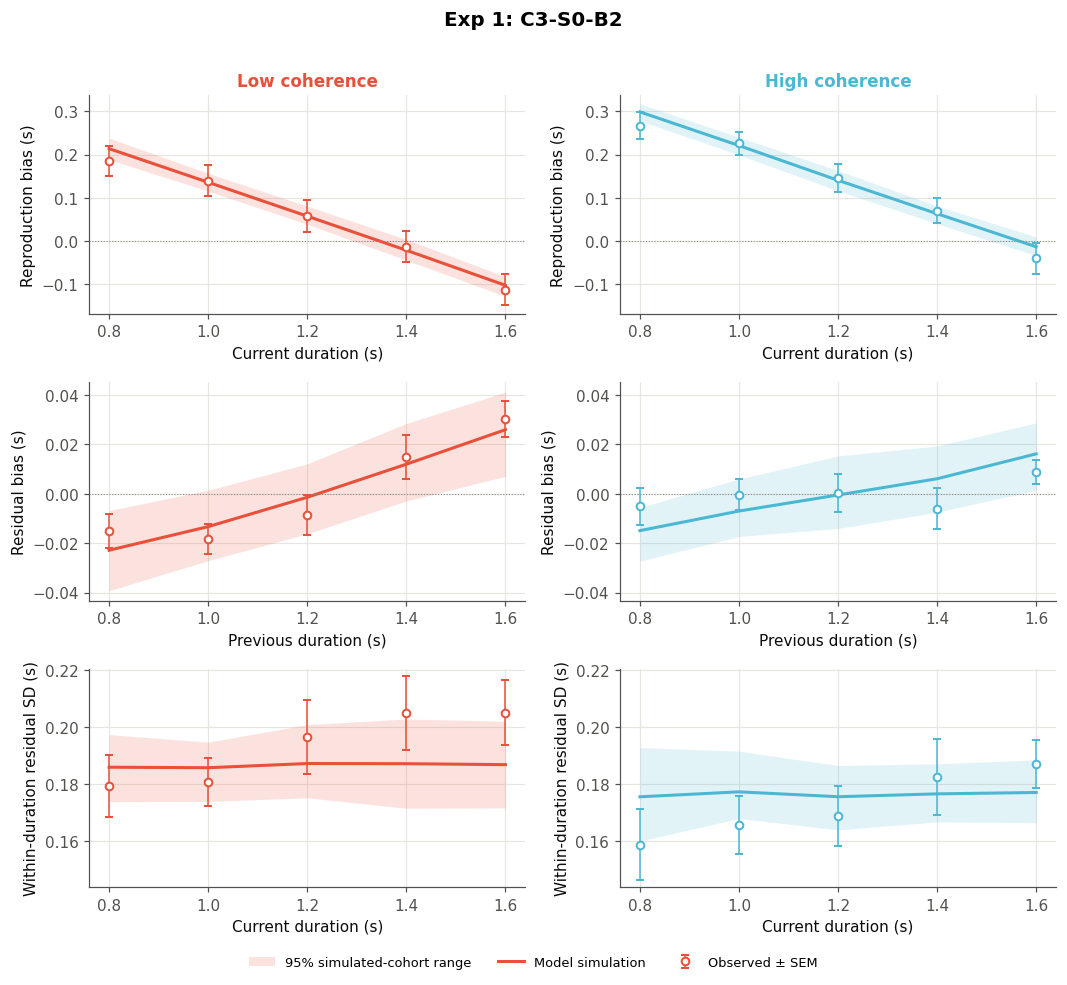

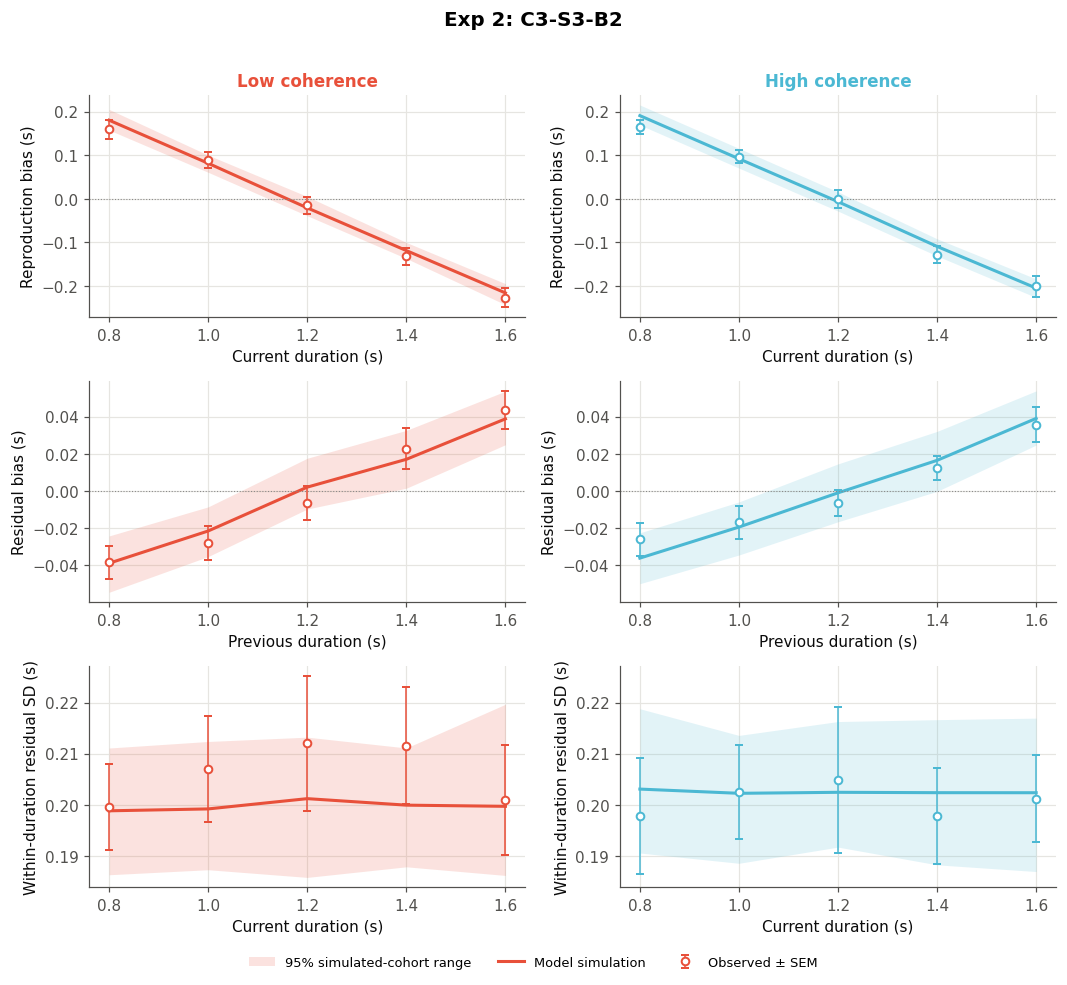

In [8]:
for e in EXPS:
    R.plot_duration_curves(ppc_c, e, PPC_MODEL[e])
    plt.show()

### 3.3 Bias by previous duration (Figure 7A–D)

* Mean reproduction bias (not residualized) by previous duration.
* Top row: grouped by current coherence. Bottom row: grouped by whether coherence repeated (Same) or switched (Switch).
* Points show the data mean ± SEM; the dashed line is the model mean over the 100 cohorts, with the 95% cohort band.

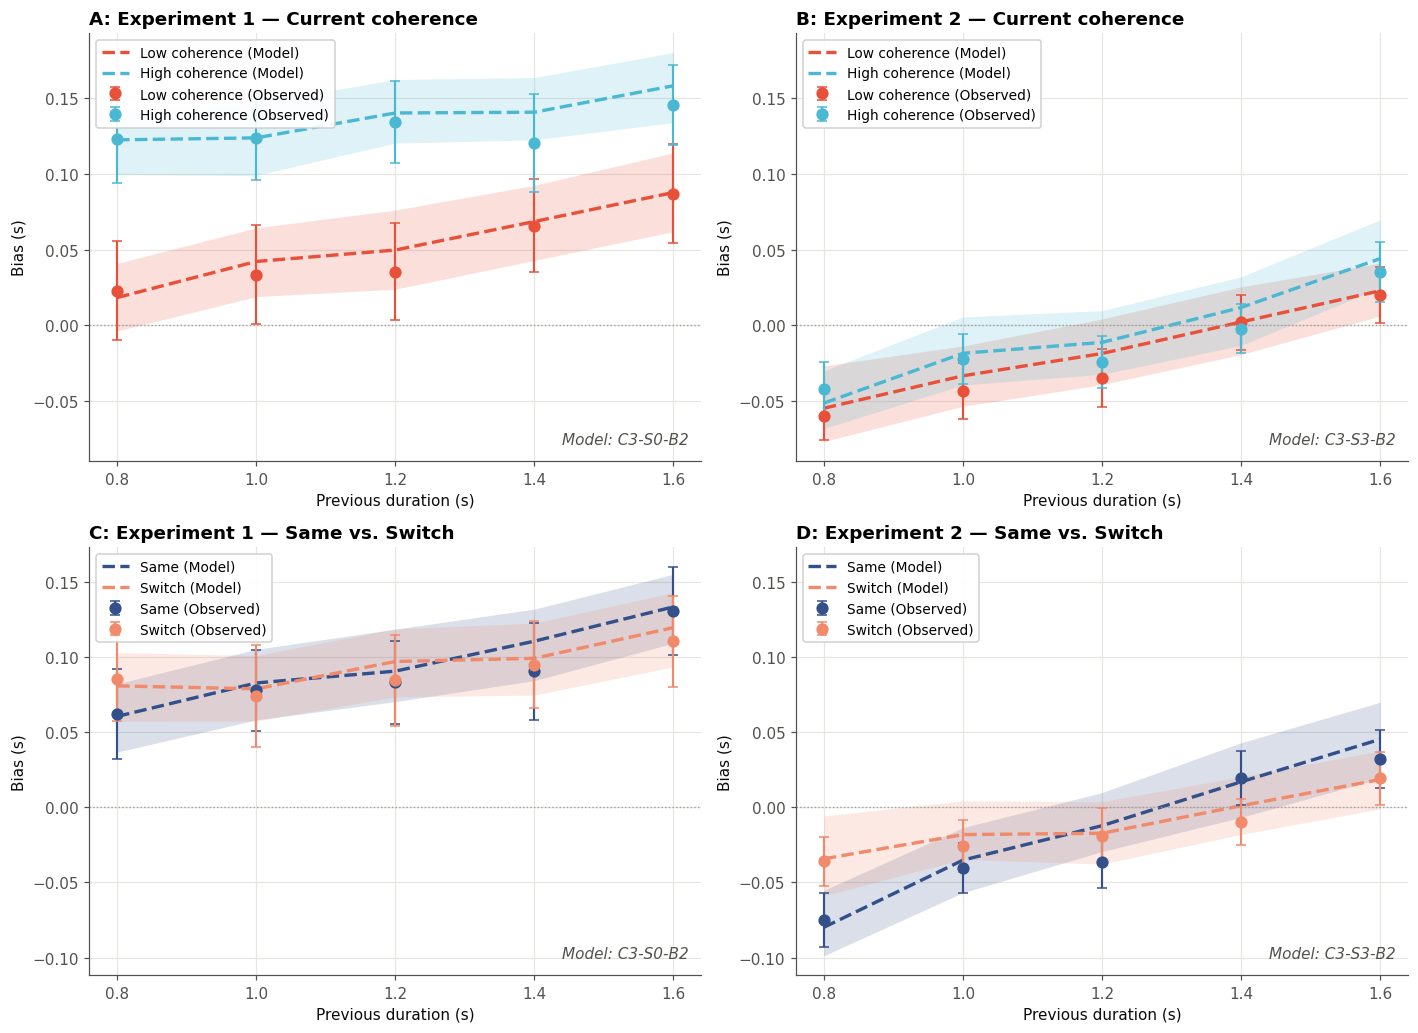

In [9]:
R.plot_history_curves(ppc_h, PPC_MODEL)
plt.show()

**Reading.** Rows below are model mean [95% cohort range] against the data mean ± SEM.

* **Central tendency.** Matched in both experiments. In Experiment 2 the High slope is slightly steeper in the model
  (−.496 [−.525, −.465] against −.477 ± .031), but the data lie inside the range.
* **Response variability.**
  * Experiment 1: High is matched. The model places Low slightly low (.187 [.179, .194] against .197 ± .009).
  * Experiment 2: matched.
  * By duration (§3.2): the model's residual SD is flat across durations. In Experiment 1 the data rise with duration
    (Low .18 → .20, High .16 → .19), so the model is too high at short and too low at long durations. On the linear
    scale, report noise does not grow with duration. Experiment 2 has no clear trend.
* **Serial dependence.**
  * Experiment 1, C3-S0-B2: Low is exact (.065 against .065). High is too strong (.039 [.018, .063] against
    .017 ± .011); the data sit just below the range. This is the current-High overestimate.
  * Experiment 2, C3-S3-B2: Low is slightly weak and High too strong (.099 [.073, .128] against .080 ± .016). The model
    therefore gives Low and High nearly the same serial dependence. In Experiment 2 the focal pattern lies in the
    transitions (L→L against the other three), not in the current-coherence means.
* **Bias by previous duration (§3.3).**
  * Experiment 1, current coherence: the model reproduces both the level difference (bias is about .08 s higher under
    High, which is the report offset) and the rising slope of each curve. All data points lie inside the bands.
  * Experiment 2, Same vs. Switch: the data are steeper after a repeat than after a switch. The model reproduces this
    through the S3 reset: on a switch the previous fast deviation is not borrowed, so the Switch curve is flatter. The
    data lie inside the bands at every previous duration.
  * The two remaining panels (Experiment 1 Same vs. Switch, Experiment 2 current coherence) show no clear separation
    in the data, and the model curves overlap there too.

## 4. Parameters and Kalman gains

Figure 6 and Table B2 of the manuscript show these quantities. Here: one x axis, and two bars per quantity, Experiment 1 (C3-S0-B2) and Experiment 2 (C3-S3-B2). Bars are the mean over participants ± SEM, and
the number on each bar is its mean.

* **Parameters.**
  * $q_1$ and $q_2$ are the process noises of the fast and slow states, in units of the High-coherence measurement
    variance $R=1$.
  * $\sigma_b$ is the B2 response-bias drift per trial, in seconds:
    $\sigma_b=\sqrt{q_3^{\text{eff}}}$, the SD of $\eta_i$ in $b_i=\lambda b_{i-1}+\eta_i$. This is the quantity the
    likelihood uses. It is shown under current Low and High.
  * $\alpha_{q_3}$ is its coherence modulation, $q_3^{\text{eff}}=q_3\exp(\alpha_{q_3}(1-\mathrm{coh}))$, so a positive
    value means more bias drift under Low.
  * $\lambda$ is the bias decay.
  * $\phi^L$ and $\phi^H$ are the readout persistence under current Low and High.
* **Kalman gains** by current coherence, as means over that coherence's trials:
  * the duration measurement gain $K^{(x)}$;
  * the memory gain $K^{(m)}$;
  * the readout weight $(1-K^{(x)})\,\phi$ on the previous fast deviation.

The table compares Low and High within each experiment: medians, the number of participants with Low > High, and a
two-sided Wilcoxon signed-rank test.

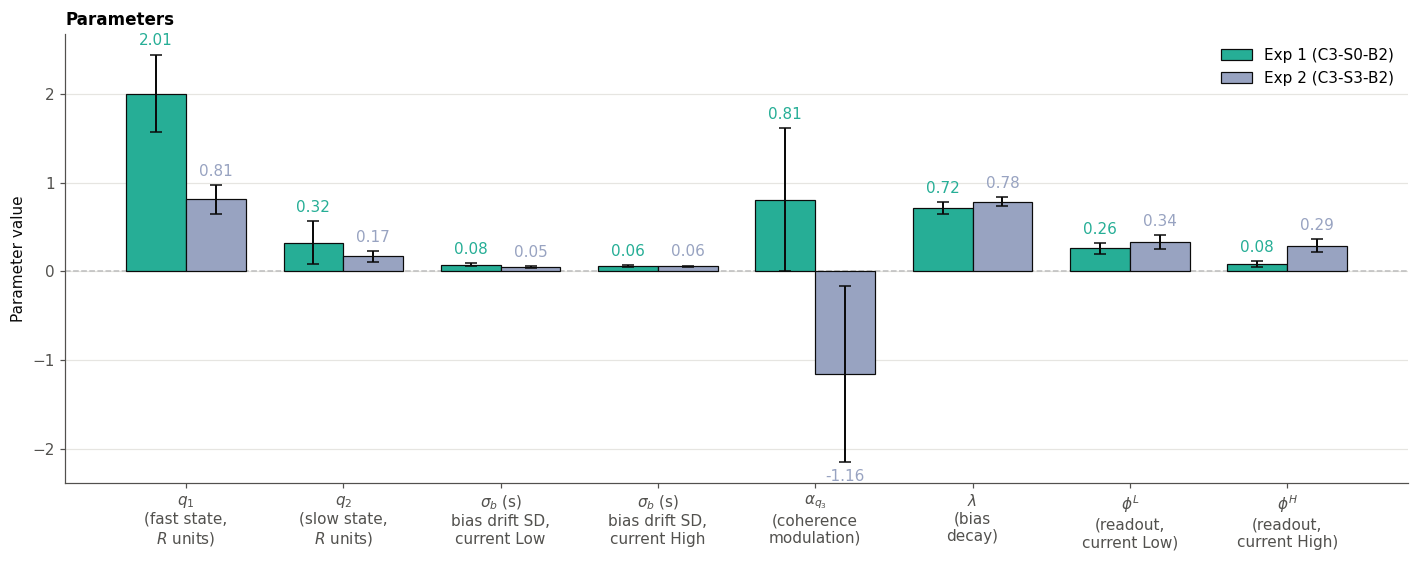

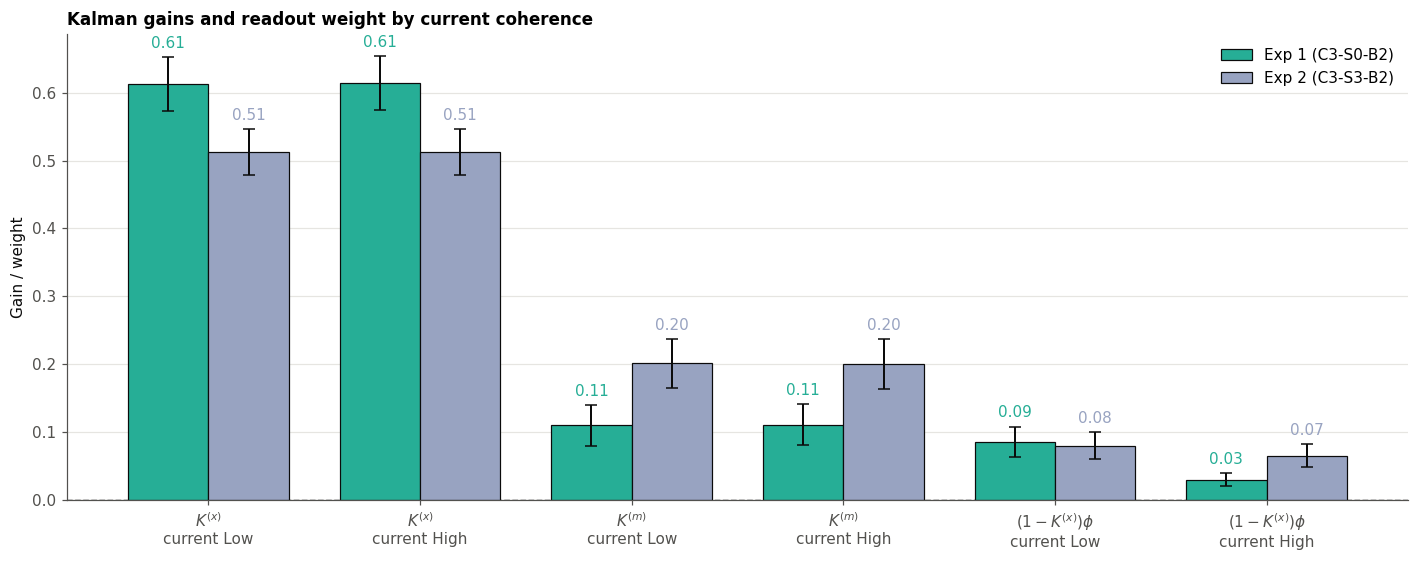

median_Low  median_High Low_gt_High  wilcoxon_p
experiment model    quantity                                                                              
Exp 1      C3-S0-B2 φ                                           0.182        0.000       14/22       0.003
                    K(x)                                        0.639        0.640        7/22       0.388
                    K(m)                                        0.045        0.049        7/22       0.443
                    readout weight (1−K(x))φ                    0.045        0.000       14/22       0.014
                    α_q3 (> 0: more bias noise under Low)         NaN          NaN       16/22       0.157
Exp 2      C3-S3-B2 φ                                           0.178        0.202       10/22       0.668
                    K(x)                                        0.527        0.528       11/22       0.726
                    K(m)                                        0.182        0.174       11/22       0.750
                    readout weight (1−K(x))φ                    0.048        0.032       11/22       0.622
                    α_q3 (> 0: more bias noise under Low)         NaN          NaN        9/22       0.683

In [10]:
PAR = R.participant_quantities(FITS, SEL)
R.plot_parameters(PAR, SEL)
R.plot_gains(PAR, SEL)
plt.show()
display(R.low_high_tests(PAR, SEL))

**Reading.**

* **Parameters.**
  * Experiment 1 has more fast-state noise than Experiment 2 ($q_1$ 2.01 against 0.81) and a positive $\alpha_{q_3}$:
    more bias drift under Low, in 16 of 22 participants, though the signed-rank test is not significant, $p=.16$.
  * The response-bias drift $\sigma_b$ is a few tens of milliseconds per trial. Median under Low and High:
    Experiment 1 .067 and .052 s; Experiment 2 .030 and .044 s.
  * In Experiment 2, $\alpha_{q_3}$ is negative on average but varies widely ($p=.68$).
  * $\lambda$ is similar in the two experiments (.72 and .78).
  * The readout persistence differs by current coherence only in Experiment 1: $\phi^L$ .26 against $\phi^H$ .08
    (medians .18 and 0, 14 of 22, $p=.003$). In Experiment 2 the two are equal (.34 and .29, $p=.67$).
* **Kalman gains.**
  * $K^{(x)}$ is the same under Low and High (Experiment 1 .61 and .61, Experiment 2 .51 and .51), and so is
    $K^{(m)}$ (.11 and .11; .20 and .20); all $p>.38$. The model therefore predicts the same central tendency under
    both coherences, as in the data.
  * Experiment 2 has the higher memory gain and the lower measurement gain. This gives a stronger pull toward memory,
    and with it the larger serial dependence of Experiment 2.
* **Readout weight.** Current coherence changes serial dependence only through the readout weight $(1-K^{(x)})\phi$:
  * Experiment 1: .09 under Low against .03 under High ($p=.014$).
  * Experiment 2: .08 and .07 ($p=.62$). The S3 reset on switch trials carries the Experiment 2 pattern (§5).

## 5. Where serial dependence comes from: memory path and readout path

From the engine's linear maps: $\partial\hat u_i/\partial s_{i-1}=\mathbf c_i\,\mathbf K_{i-1}$. The memory path is the
same quantity with $\phi=0$ (the memory filter does not depend on $\phi$); the readout path is the difference. Means
over trials of each transition and over participants, for the selected models.

In [11]:
display(R.decompose(FITS, SEL))

Kx_current  memory  readout  total
experiment model    transition                                    
Exp 1      C3-S0-B2 L→L              0.612   0.029    0.044  0.073
                    H→L              0.612   0.030    0.044  0.073
                    L→H              0.611   0.029    0.016  0.045
                    H→H              0.611   0.029    0.016  0.044
Exp 2      C3-S3-B2 L→L              0.510   0.088    0.050  0.138
                    H→L              0.511   0.088    0.000  0.088
                    L→H              0.511   0.089    0.000  0.089
                    H→H              0.510   0.088    0.035  0.123

**Reading.**

* The memory path is the same for all four transitions (Experiment 1 .03, Experiment 2 .09), because the gain does not
  depend on coherence (current gain .61 and .51).
* The memory path is the mean of $(1-K_i^{(x)})\,K_{i-1}^{(m)}$ over trials and participants. It is smaller than the
  product of the mean gains of §4 (Experiment 1: $(1-.61)\times.11=.04$ against .03), because participants with a high
  $K^{(m)}$ also tend to have a high $K^{(x)}$.
* **Experiment 1:** the readout path is .044 when the current trial is Low and .016 when it is High. That gives the
  Low − High difference. The .016 on current-High trials comes from the participants with $\phi^H>0$, and it is the
  source of the overestimate in §3.
* **Experiment 2:** the S3 reset sets the readout path to 0 on the two switch transitions. L→L (.050) and H→H (.035)
  keep it, so H→H is predicted almost as high as L→L (.123 against .138), while the data have .083.

# Summary

1. **Model.** The memory filter has no persistence. $\phi$ acts only at the readout, after the stimulus, and is not
   written back: $\hat x_i=(1-K_i^{(x)})\hat m_{i-1}+K_i^{(x)}s_i$, $\hat u_i=\hat x_i+(1-K_i^{(x)})\,\phi_i\,\hat f_{i-1}$.
   Central tendency is $K_i^{(x)}$. Serial dependence is $(1-K_i^{(x)})\big[K^{(m)}_{i-1}+\phi_i(K^{(x)}_{i-1}-K^{(m)}_{i-1})\big]$
   for B0 and B2 without S1; S1 and B1 change the bracket (Part I). The closed form and the slopes match the engine
   to numerical precision.
2. **Selection.** B2 is clearly preferred. S0 is preferred in Experiment 1, and S3 is needed in Experiment 2 for the
   focal L→L contrast. The C level is not identified, and the gain does not depend on coherence for any C level. C3 is
   chosen in both experiments: it is within 0.12 (Experiment 1) and 0.56 (Experiment 2) AIC units of the optimum, is
   tied for the smallest parameter count, and passes response variability.
3. **Behaviour (100-cohort predictive check).** Central tendency and response variability are reproduced. The
   exceptions are a slightly low Low residual SD in Experiment 1 and residual SD that does not grow with duration.
   Serial dependence is reproduced when the current trial is Low, but is too strong when it is High, in both
   experiments.
4. **Mechanism.** Experiment 1: $\phi^L>\phi^H$ in the readout. Experiment 2: the S3 reset on switches. The remaining
   misfit is the readout path on current-High trials.
5. **Recovery.** Parameter and model recovery are in `recovery.ipynb` (Appendix B.5–B.6).